
#**Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones**

##**Edición 2026**

---

# Trabajo práctico entregable - Parte 2
---
Grupo 5:



*   Bencharski, Constaza
*   Castro, Gerónimo
*   Riego, Daniela
*   Sequeiros, Gerónimo

Fecha:

      27/04/2026





In [41]:
import io
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

#seaborn.set_context('talk')

## Lectura del dataset

Cargamos los datos, y observamos en primera instancia el tamaño de los datos que estamos manejando

In [42]:
# Importacion del dataframe
url     = 'https://raw.githubusercontent.com/DiploDatos/AnalisisyVisualizacion/refs/heads/master/sysarmy_survey_2026_processed.csv'
df_raw  = pd.read_csv(url)
df      = df_raw.copy()
print('Tamaño del Dataframe',df.shape)

Tamaño del Dataframe (4939, 60)


Observamos los distintos géneros cargados en el Dataset

In [43]:
df.profile_gender.unique()

array(['Mujer Cis', 'Hombre Cis', 'Prefiero no decir', 'Trans', 'Queer',
       'No binarie', 'Agénero', nan], dtype=object)

In [44]:
df.loc[:,'profile_g'] = df.profile_gender.replace({'Hombre Cis': 'Varón cis','Mujer Cis': 'Mujer cis','Queer':'Diversidades','Trans':'Diversidades','Queer':'Diversidades','Lesbiana':'Diversidades','Agénero':'Diversidades'}).fillna(False)

Filtramos los datos en función de los valores razonables para el salario neto, y generamos dos dataframes: uno para los hombres cis y otro para las mujeres cis

In [45]:
# Definición de los grupos de salario para varon cis y mujer cis.
is_man = df.profile_g == 'Varón cis'
is_woman = df.profile_g == 'Mujer cis'
groupA = df[(15000000>df.salary_monthly_NETO)&(df.salary_monthly_NETO > 360000) & is_man].salary_monthly_NETO
groupB  = df[(15000000>df.salary_monthly_NETO)&(df.salary_monthly_NETO > 360000) & is_woman].salary_monthly_NETO


Y hacemos una primera visualización de la distribución de salarios

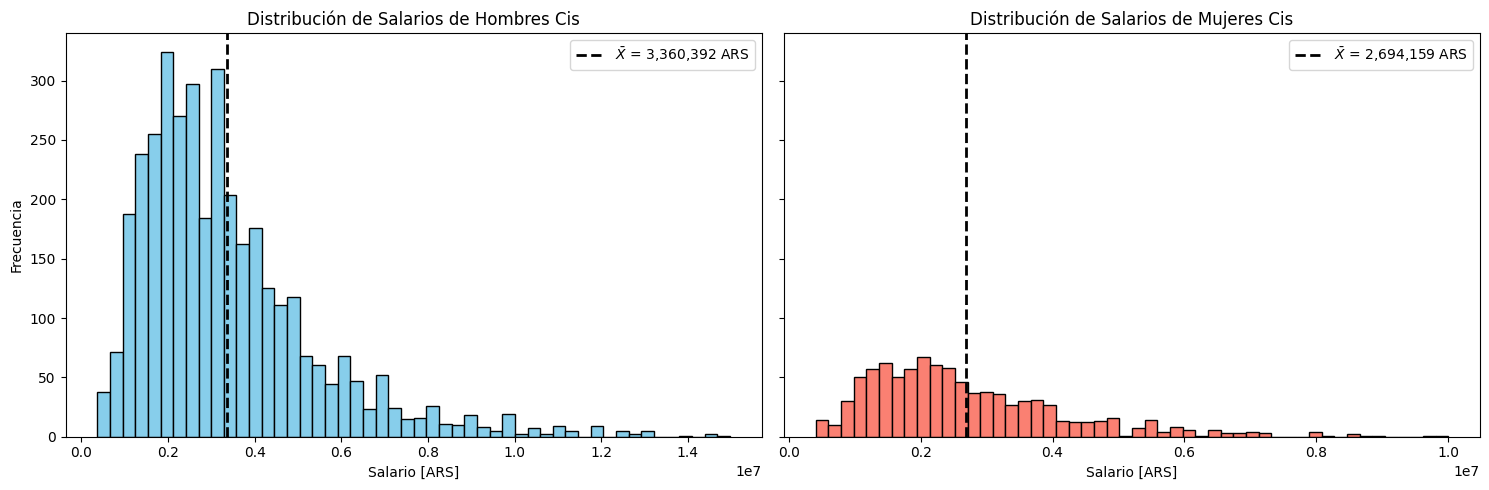

In [46]:
# Grafico con histogramas y valores medios
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Panel A
axes[0].hist(groupA, bins=50, color='skyblue', edgecolor='black')
# media y desviacion
axes[0].axvline(groupA.mean(), color='k', linestyle='--', linewidth=2,
                label=rf'$\bar{{X}}$ = {groupA.mean():,.0f} ARS')

axes[0].set_title('Distribución de Salarios de Hombres Cis')
axes[0].set_xlabel('Salario [ARS]')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# Panel B
axes[1].hist(groupB, bins=50, color='salmon', edgecolor='black')
# media y desviacion
axes[1].axvline(groupB.mean(), color='k', linestyle='--', linewidth=2,
                label=rf'$\bar{{X}}$ = {groupB.mean():,.0f} ARS')

axes[1].set_title('Distribución de Salarios de Mujeres Cis')
axes[1].set_xlabel('Salario [ARS]')
axes[1].legend()

plt.tight_layout()
plt.show()



## Ejercicio 1: Estimación

**Consigna:**  Calcular una estimación puntual y un intervalo de confianza de nivel (1-alpha) para la resta entre la media del salario Neto para Hombres y la media del salario Neto para mujeres (diferencia de las medias entre el grupoA y grupoB).
¿Cómo se relaciona este intervalo de confianza con el test de hipótesis para diferencia de medias?

Cada observación corresponde a un individuo independiente que respondió la encuesta, y cada grupo reune a individuos distintos.

In [47]:
# Cuántas observaciones hay sobre cada grupo?
print('Observaciones sobre el grupo de varones:', len(groupA))
print('Observaciones sobre el grupo de mujeres:', len(groupB))

Observaciones sobre el grupo de varones: 3635
Observaciones sobre el grupo de mujeres: 924


Se dispone de muestras grandes para ambos grupos, por lo que resulta apropiado realizar inferencia estadística sobre sus medias.

Considerando el TCL, las medias muestrales de ambos grupos pueden considerarse aproximadamente normales, independientemente de la distribución original de los salarios. En consecuencia, la diferencia entre las medias muestrales también sigue aproximadamente una distribución normal. Esto permite justificar la construcción de un intervalo de confianza para la diferencia de medias entre ambos grupos.

In [48]:
# Estimación puntual de la diferencia
dif_medias = groupA.mean() - groupB.mean()
print(f"Estimación puntual de la diferencia de medias (Hombres - Mujeres): {dif_medias:.2f}")

Estimación puntual de la diferencia de medias (Hombres - Mujeres): 666233.53


El estimador puntual nos da una diferencia de 666233 ARS entre medias salariales de ambos grupos.

Ahora queremos construir el intervalo de confianza del 95% epara esta diferencia. La diferencia de las medias sigue una distribución normal por el TCL. Construimos un intervalo bilateral centrado en la diferencia observada que contiene el 95% de la distribución del estimador. Si dicho intervalo no contiene al cero, puede rechazarse la hipótesis nula de igualdad de medias.

Para la estimación del intervalo de coonfianza utilizaremos la distribución $t$ de Welch, dado que contamos con dos muestras independientes con parámetros de dispersión distintos.

In [49]:
# Calculamos los parámetros de dispersión
s_A = groupA.std()
s_B = groupB.std()
n_A = len(groupA)
n_B = len(groupB)

# Error estándar de la diferencia de medias
se_dif_medias = np.sqrt((s_A**2/n_A) + (s_B**2/n_B))

# Y calculamos la Grados de libertad de Welch
df_welch = (se_dif_medias**4) / ((s_A**2/n_A)**2/(n_A-1) + (s_B**2/n_B)**2/(n_B-1))
print(f"Grados de libertad de Welch: {df_welch:.2f}")


Grados de libertad de Welch: 1884.24


Armamos el intervalo de confianza bilateral de Welch

In [50]:
# Valor crítico para el intervalo de confianza
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df_welch) # El IC de Welch es bilateral entonces usamos alpha/2

# Armamos el IC
IC_min = dif_medias - t_crit * se_dif_medias
IC_max = dif_medias + t_crit * se_dif_medias
print(f"Intervalo de confianza (IC) del {(1-alpha)*100}%: ({IC_min:.2f}, {IC_max:.2f})")


Intervalo de confianza (IC) del 95.0%: (547828.66, 784638.40)


### Relación con el Test de Hipótesis
El IC obtenido contiene los valores posibles para la diferencia de las medias, dado el nivel de confianza $1-\alpha$.

En un test de hipótesis

 $H_0: \mu_A-\mu_B = 0$

 $H_1: \mu_A-\mu_B \ne 0$

Dado que el IC del $95$% es

$$[547.828 , 784.638]$$

el valor $0$ está contenido. Por lo tanto, se rechaza la hipótesis nula $H_0$ en favor de $H_1$.
En consecuencia, existe evidencia estadísticamente significativa de una diferencia entre los salarios medios de ambos grupos.

## Ejercicio 2: Test de hipótesis




### 2.1 Formalización (Alternativa 1)

Describir formalmente los distintos componentes de un test de hipótesis para comprobar si la distribución de los salarios es distinta entre los grupos A y B.

**Hipótesis Nula**

$H_0 : \mu_{A} - \mu_{B} =0 $

**Hipótesis Alternativa**

$H_1 : \mu_{A} - \mu_{B} \neq 0 $

**Estadístico (Pivote)**

En este caso, el estadístico de prueba es:$$T = \frac{(\bar{X}_A - \bar{X}_B) - (\mu_A - \mu_B)}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$$

Bajo la suposición de la hipótesis nula ($H_0: \mu_A - \mu_B = 0$), el estadístico se simplifica a:$$T = \frac{\bar{X}_A - \bar{X}_B}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$$

Bajo $H_0$ este estadístico sigue aproximadamente la distribución $t$-Welch con $\nu$ grados de libertad dados por la aproximación Welch-Satterthwaite:

$$T \approx t_{ν}$$

El intervalod econfianza $1-\alpha$ es tal que

$$P(-t_{\nu,1-\alpha/2}\leq T \leq t_{\nu,1−\alpha/2})\approx 1-\alpha$$

Y el criterio de decisión para un test bilateral es aceptar $H_0$ si $|{T}|\leq t_{\nu,1-\alpha/2}$. Caso contrario se rechaza $H_0$ en favor de $H_1$.

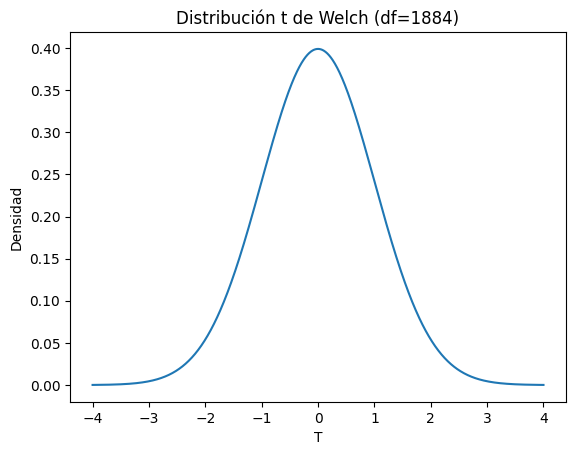

In [51]:
from scipy.stats import t

# Rango de valores
x = np.linspace(-4, 4, 1000)

# Densidad t
y = t.pdf(x, df_welch)

# Graficar
plt.plot(x, y)
plt.title(f"Distribución t de Welch (df={df_welch:.0f})")
plt.xlabel("T")
plt.ylabel("Densidad")
plt.show()

In [52]:
#Cálculo del P-valor:
res = stats.ttest_ind(groupB, groupA, equal_var=False, nan_policy="omit" , alternative='two-sided')
p_valor = res.pvalue


print(f"P-valor: {p_valor:.50f}")

P-valor: 0.00000000000000000000000000175748650478501328283839


Dado que $p\text{-valor} = 1.7*10^{-27} < \alpha$ = 0.05, se rechaza la hipótesis nula.
Por lo tanto, se puede afirmar con un 95% de confianza que las medias de los salarios entre mujeres y hombres **son distintas** para la muestra analizada.

Otra forma de visualizar la evaluación del test de hipótesis planteado es comparando el valor observado de t con el valor crítico, como sigue:

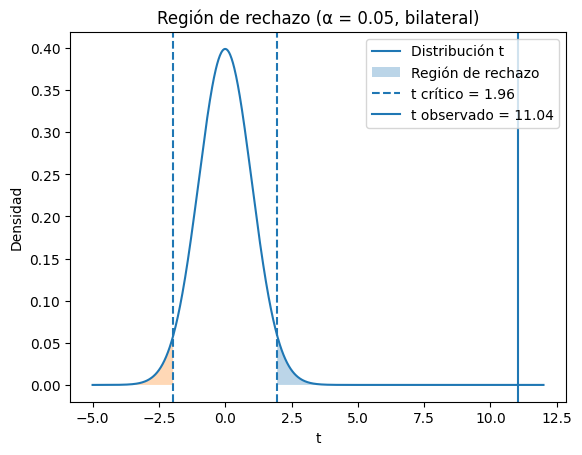

In [53]:
t_obs = dif_medias / se_dif_medias

t_crit = t.ppf(1 - alpha/2, df_welch)
# eje x
x = np.linspace(-5, 12, 1000)
y = t.pdf(x, df_welch)

plt.plot(x, y, label="Distribución t")

# Regiones de rechazo (colas)
x_fill_right = np.linspace(t_crit, 12, 500)
x_fill_left = np.linspace(-5, -t_crit, 500)

plt.fill_between(x_fill_right, t.pdf(x_fill_right, df_welch), alpha=0.3, label="Región de rechazo")
plt.fill_between(x_fill_left, t.pdf(x_fill_left, df_welch), alpha=0.3)

# Líneas críticas
plt.axvline(t_crit, linestyle='--', label=f"t crítico = {t_crit:.2f}")
plt.axvline(-t_crit, linestyle='--')
plt.axvline(t_obs, linestyle='-', label=f"t observado = {t_obs:.2f}")

plt.title("Región de rechazo (α = 0.05, bilateral)")
plt.xlabel("t")
plt.ylabel("Densidad")
plt.legend()
plt.show()

Como el valor observado de t cae dentro de la región de rechazo, se rechaza la hipótesis nula.

### Desarrollo (Alternativa 2)

Como segunda alternativa, se decidió estudiar estrictamente la distribución de los salarios, para plantear el test de hipótesis.


Primero visualizamos las distribuciones de los salarios. Estas suelen seguir una función lognormal, es decir, el logaritmo del salario sigue una distribución normal.

In [54]:
#----------------------------------------------------
# Funciones para visualizar distribuciones ajustadas
#----------------------------------------------------

# Función para plotear ajuste normal
def plot_normal_hist(serie_salarios, ax,
                     bins_edges,
                     color='skyblue',
                     label=''):

    # ajuste normal
    mu, sigma = stats.norm.fit(serie_salarios)

    # histograma en counts
    counts, bins, _ = ax.hist(serie_salarios, bins=bins_edges,
        density=False, color=color, alpha=0.45,
        edgecolor="black")

    # curva normal reescalada a counts
    xx = np.linspace(bins_edges[0], bins_edges[-1], 500)

    bin_width = bins_edges[1] - bins_edges[0]
    yy = stats.norm.pdf(xx, mu, sigma) * len(serie_salarios) * bin_width
    # Plot
    ax.plot(xx, yy, color=color, lw=2.5, label=label)

# Función para plotear ajuste lognormal
def plot_lognormal_hist(serie_salarios, ax,
                        bins_edges,
                        color='skyblue',
                        label=''):

    # ajuste lognormal
    shape, loc, scale = stats.lognorm.fit(serie_salarios, floc=0)

    # histograma con matplotlib
    counts, bins, _ = ax.hist(serie_salarios, bins=bins_edges,
        density=False, color=color, alpha=0.45,
        edgecolor="black")

    # curva lognormal reescalada a counts
    xx = np.linspace(bins_edges[0], bins_edges[-1], 500)

    bin_width = bins_edges[1] - bins_edges[0]
    yy = stats.lognorm.pdf(xx, shape, loc, scale) * len(serie_salarios) * bin_width
    # Plot
    ax.plot(xx, yy, color=color, lw=2.5, label=label)



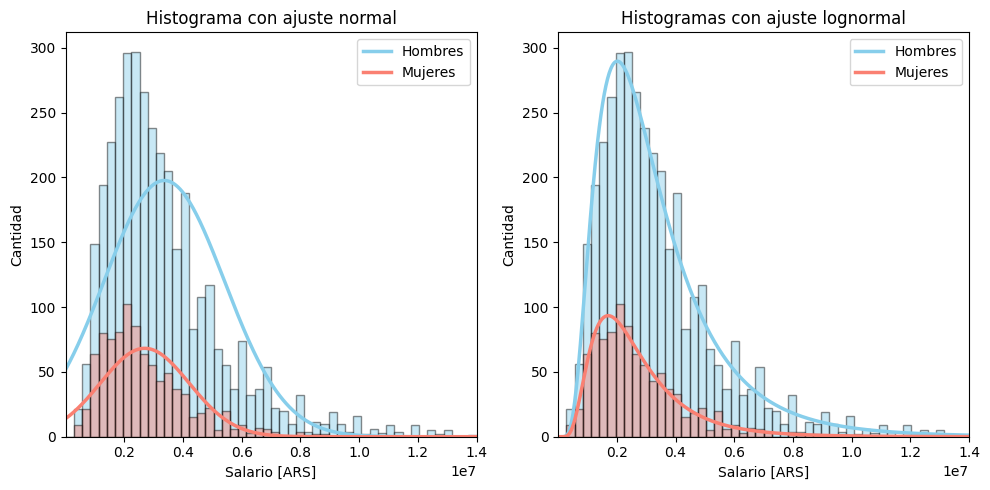

In [55]:
# Visualización de distribuciones

# rango fijo
rango = (1, 14000000)
# bins idguales
bins_edges = np.linspace(rango[0], rango[1], 51)

# Figura
fig, axes = plt.subplots(1, 2, figsize=(10,5))

# Panel 1 (normal)
plot_normal_hist(groupA, axes[0], bins_edges,
                    color='skyblue', label='Hombres')

plot_normal_hist(groupB, axes[0], bins_edges,
                    color='salmon', label='Mujeres')

axes[0].set_xlim(rango)
axes[0].set_xlabel("Salario [ARS]")
axes[0].set_ylabel("Cantidad")
axes[0].set_title("Histograma con ajuste normal")
axes[0].legend()


# Panel 2 (lognormal)
plot_lognormal_hist(groupA, axes[1], bins_edges,
                 color='skyblue', label='Hombres')

plot_lognormal_hist(groupB, axes[1], bins_edges,
                 color='salmon', label='Mujeres')

axes[1].set_xlim(rango)
axes[1].set_xlabel("Salario [ARS]")
axes[1].set_ylabel("Cantidad")
axes[1].set_title("Histogramas con ajuste lognormal")
axes[1].legend()

plt.tight_layout()
plt.show()

A partir de esta visualización, vemos que la distribución de salarios se describe mejor con un ajuste lognormal.

Para nuestro test de hipótesis vamos a utilizar estas nuevas variables

$$Y_A = \log(X_A)$$

$$Y_B = \log(X_B)$$

### Test de hipótesis
$$H_0: \bar{Y_A} - \bar{Y_B} = 0$$

$$H_1: \bar{Y_A} - \bar{Y_B} \ne 0$$

Ahora, bajo la hipótesis nula $\bar{Y}_A - \bar{Y}_B$ sigue una distribución normal centrada en cero.  

El estadístico que vamos a usar es, nuevamente, la distribucion $t$ de Welch porque se comparan medias de dos muestras independientes sin asumir igualdad de varianzas.

**Estadístico (Pivote)**

En este caso, el estadístico de prueba bajo $H_0$ es:

$$T = \frac{\bar{Y}_A - \bar{Y}_B}{\sqrt{\frac{s_A^2}{n_A} + \frac{s_B^2}{n_B}}}$$

Este estadístico sigue aproximadamente la distribución $t$-Welch con $\nu$ grados de libertad dados por la aproximación Welch-Satterthwaite:

$$T \approx t_{ν}$$

El intervalod econfianza $1-\alpha$ es tal que

$$P(-t_{\nu,1-\alpha/2}\leq T \leq t_{\nu,1−\alpha/2})\approx 1-\alpha$$

Y el criterio de decisión para un test bilateral es aceptar $H_0$ si $|{T}|\leq t_{\nu,1-\alpha/2}$. Caso contrario se rechaza $H_0$ en favor de $H_1$.



In [56]:
# Nuevas variables aleatorias que siguen una distribucion normal
Y_A = np.log(groupA)
Y_B = np.log(groupB)
# Desviaciones
s_YA = Y_A.std()
s_YB = Y_B.std()
n_A = len(groupA)
n_B = len(groupB)
# Error estandar de la diferencia de medias
SE_dif_med_Y = np.sqrt((s_YA**2/n_A) + (s_YB**2/n_B))
# Grados de libertad de Welch
df_welch = (SE_dif_med_Y**4) / ((s_YA**2/n_A)**2/(n_A-1) + (s_YB**2/n_B)**2/(n_B-1))
print(f"Grados de libertad de Welch: {df_welch:.2f}")


Grados de libertad de Welch: 1486.32


In [57]:
# Test de Welch
t_stat, p_value = stats.ttest_ind(Y_A, Y_B, equal_var=False)

print("t =", t_stat)
print("p-value =", p_value)
if p_value < alpha:
    print("Se rechaza H0: las medias difieren")
else:
    print("No se rechaza H0")



t = 9.783906541197924
p-value = 5.971065999313689e-22
Se rechaza H0: las medias difieren


Nuevamente, como el p-valor es menor al parámetro $\alpha$, se rechaza la hipótesis nula, y por lo tanto, las medias son diferentes.  

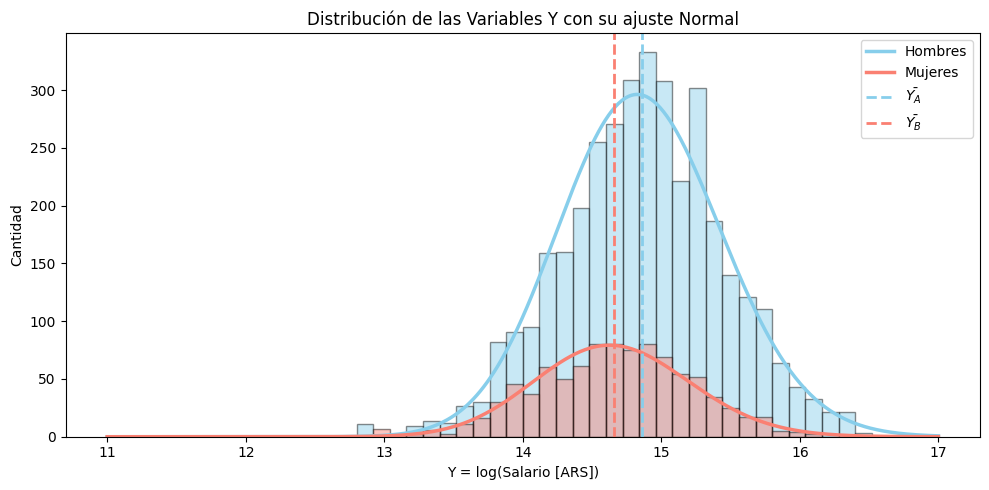

In [58]:
# Plot
# bins iguales
bins2 = np.linspace(11, 17, 51)

fig, axes = plt.subplots(1, 1, figsize=(10,5))

plot_lognormal_hist(Y_A, axes, bins2,
                 color='skyblue', label='Hombres')

plot_lognormal_hist(Y_B, axes, bins2,
                 color='salmon', label='Mujeres')

# media y desviacion
axes.axvline(Y_A.mean(), color='skyblue', linestyle='--', linewidth=2,
                label=rf'$\bar{{Y_A}}$')
axes.axvline(Y_B.mean(), color='salmon', linestyle='--', linewidth=2,
                label=rf'$\bar{{Y_B}}$')


axes.set_xlabel("Y = log(Salario [ARS])")
axes.set_ylabel("Cantidad")
axes.set_title("Distribución de las Variables Y con su ajuste Normal")
axes.legend()

plt.tight_layout()
plt.show()


### [Opcional] 2.3 Potencia del test

Nuestra muestra, ¿era lo suficientemente grande para detectar si existe o no una diferencia entre los grupos?

1. Utilice la función `tt_ind_solve_power` para calcular el tamaño necesario de la muestra para un poder estadístico de 0.8, 0.9 y 0.95, asumiendo una significancia estadística de 0.05.
2. ¿Cómo intepretan el poder estadístico de un test? Dado su conocimiento de dominio sobre los datos, ¿les parece que esta muestra es lo suficientemente grande para ser representativo de la tendencia general? ¿y para utilizarlo en un juicio penal contra una empresa XX por una causa de discriminación?

[Documentación](https://www.statsmodels.org/stable/generated/statsmodels.stats.power.tt_ind_solve_power.html)

NOTA: este análisis debería hacerse ANTES de recolectar los datos.

In [59]:
from statsmodels.stats.power import tt_ind_solve_power

In [60]:
n=len(df.salary_monthly_NETO)

effect_size = (groupA.mean() - groupB.mean()) / groupB.std()
alpha = 0.05
ratio = len(groupB) / len(groupA)
power= [0.8 , 0.9 , 0.95]

In [61]:
for power_value in power:
  n_muestra = tt_ind_solve_power(effect_size=effect_size, nobs1= None, alpha=alpha,power=power_value,  ratio=ratio)
  print(f"\n Tamaño de muestra para un poder estadístico de {power_value:.2f}, con una significancia de {alpha:.2f}: {n_muestra:.2f}")
  print(f"El tamaño de nuestra muestra es {n/n_muestra:.2f} veces más grande que el necesario")


 Tamaño de muestra para un poder estadístico de 0.80, con una significancia de 0.05: 201.71
El tamaño de nuestra muestra es 24.49 veces más grande que el necesario

 Tamaño de muestra para un poder estadístico de 0.90, con una significancia de 0.05: 269.50
El tamaño de nuestra muestra es 18.33 veces más grande que el necesario

 Tamaño de muestra para un poder estadístico de 0.95, con una significancia de 0.05: 332.93
El tamaño de nuestra muestra es 14.83 veces más grande que el necesario


## Conclusión:
El poder del test del 0.8 sugiere que que hay un 80$\%$ de probabilidades de detectar un efecto real y un 20$\%$ de cometer un Error Tipo II. Es decir, no detectar una diferencia que sí existe.

Dado que para el máximo poder del test (95%), con significancia del 95%, la muestra tomada excede casi 15 veces la necesaria para que el t-test tenga 95% de probabilidades de detectar el efecto real en la diferencia de las medias.

En cuanto a la representatividad de la muestra, podemos decir que la misma es representativa siempre y cuando se analice en el contexto de "de dónde" y "cómo" se tomaron los datos, por ejemplo, sabemos que la mayoría de los mismos vienen de la provinicia de Buenos Aires, y podemos conocer también los niveles de seniority y estudios alcanzados, por lo que se podría discutir la representatividad de la muestra sobre la población contextualizada en esos términos. En términos de la potencialidad del test, el tamaño de la muestra es más que suficiente para los parámetros enunciados.

En cuánto a la utilización en un juicio por discriminación, informar solamente el hecho de tener una muestra más grande de la necesaria (15 veces) o de tener un p-valor bajo no son hechos concluyentes de por sí, puesto que tener una muestra tan grande hace extremádamente sensible al p-valor, por lo que este podría detectar diferencias de las medias de salarios que sean ínfimas, y no representativas de una brecha salarial. Sin embargo, si lo ponemos en contexto con resultados anteriores, tenemos que:

1.   El estimado puntual de la diferencia de las medias es más de 9 veces superior a su error estándar, e informa una brecha salarial del 25% entre hombres y mujeres, lo que supone que las diferencias, además de detectables por nuestro test, **son significativas**
2.   La diferencia se mantiene tanto en la media cómo en la mediana de los datos, lo que sugiere que esta no se debe a valores extremos.

Por los dos puntos expuestos, sumados a la potencia del test del 95%, y el p-valor extremádamente bajo, podríamos utilizar esto como evidencia de discriminación en una empresa, siempre que los datos se hayan tomado de manera representativa.


## Ejercicio 3: Comunicación y visualización

**Consigna:** Seleccionen un resultado que les parezca relevante a partir de alguno de los ejercicios del entregable. Diseñe e implemente una comunicación en base a este mensaje, en un archivo PDF.

Elija las palabras y visualización más adecuada para que la comunicación sea entendible, efectiva y se dapte a UNA de las siguientes situaciones:

1. Una sección en un artículo de difusión a presentar como parte de una organización sin fines de lucro.
No más de 1 página A4 (o dos si los gráficos son muy grandes).
  1. Ejemplo: Alguna de las secciones [Los ecosistemas de emprendimiento de América Latina y el Caribe frente al COVID-19: Impactos, necesidades y recomendaciones](https://publications.iadb.org/es/los-ecosistemas-de-emprendimiento-de-america-latina-y-el-caribe-frente-al-covid-19-impactos-necesidades-y-recomendaciones), por ejemplo la sección *2.2. Reacciones de los emprendedores*.
  2. Ejemplo: Alguna de las secciones de [The state of gender pay gap in 2021](https://www.payscale.com/data/gender-pay-gap?tk=carousel-ps-rc-job)
  3. Puntos clave:
    1. Simpleza de los gráficos.
    2. Comunicación en lenguaje simple a personas que no son necesariamente expertos de dominio.
    2. Selección de UNA oración sobre la que se hace énfasis.
    3. No es necesario que mencionen objetivos ni descripciones del conjunto de datos, se supone que eso ya estaría explicado en otras secciones del informe.

2. Una publicación científica o reporte técnico interno. No más de una página A4:
  2. Ejemplo: La sección de resultados de [IZA DP No. 12914: The Impact of a Minimum Wage Change on the Distribution of Wages and Household Income](https://www.iza.org/publications/dp/12914/the-impact-of-a-minimum-wage-change-on-the-distribution-of-wages-and-household-income).
  2. Ejemplo: Alguna de las secciones de [Temporary reduction in daily global CO2 emissions during the COVID-19 forced confinement](https://www.nature.com/articles/s41558-020-0797-x)
  3. Puntos clave:
    3. Nivel de detalle técnico requerido. Es necesario justificar la validez del análisis.
    4. La idea presentada puede ser más compleja. Pueden asumir que la audiencia tiene conocimiento técnico y va a analizar las visualizaciones en detalle.
    5. Pueden presentar más en detalle las limitaciones del análisis (significancia estadística, etc.)
    2. No es necesario que mencionen objetivos ni descripciones del conjunto de datos, se supone que eso ya estaría explicado en otras secciones del informe.

3. Un tweet (o post de LinkedIn) para la cuenta de su empresa consultora que hace análisis de datos. El objetivo es promocionar un análisis de datos abiertos que van a incluir en su portfolio:
  1. Ejemplo: [Comparación vacunas covid](https://twitter.com/infobeautiful/status/1381577746527236098?s=20)
  2. Ejemplo: [Tweet del BID](https://twitter.com/el_BID/status/1388508583944507396?s=20). Lo valioso de este tweet es que usaron un único número para transmitir un mensaje. Puede ser algo así, o con un gráfico muy simple.
  3. Ejemplo: [Cambio climático](https://twitter.com/UNFCCC/status/1387732156190011394?s=20) Es un muy buen ejemplo, excepto que el gráfico no se lee nada y hay que entrar a la publicación original.
  3. Ejemplo: [¿Cuánto están los programadores en las empresas?](https://www.linkedin.com/posts/denis-rothman-0b034043_tech-career-work-activity-6793861923269054464-gS6y) (No verificamos la veracidad o seriedad de la fuente).
  4. Puntos clave:
    1. Su audiencia no va a mirar la visualización por más de unos segundos, y no tiene conocimiento técnico.
  3. Tienen que incluir además una *breve* descripción de cómo obtuvieron los datos que están presentando, que no entraría en el tweet.


## 3 - Desarrollo

Analizaremos la desigualdad salarial entre hombres y mujeres centrándonos en lo siguiente:

* Desigualdad a nivel general (utilzando el total de los datos)
* Desigualdad para el mismo puesto de trabajo
* Desigualdad para el mismo nivel de estudios

Vamos a acotar nuestro análisis a los trabajadores de dedicación Full-Time con salarios entre 360000 pesos (un salario mínimo) y 15 millones de pesos

Implementamos una comunicación de carácter divulgativo de los resultados obtenidos en este análisis.

In [62]:
# Filtrado de Fulltimes y en rango de salario
df_fulltime = df[(df['work_dedication'] == 'Full-Time') &
                 (15000000>df['salary_monthly_NETO']) &
                 (df['salary_monthly_NETO'] > 360000)]
print(f'Proporción del filtrado en la encuesta: {len(df_fulltime)/len(df)*100:.0f}%')

Proporción del filtrado en la encuesta: 90%


## Diferencia salarial general

Creamos nuevas series para hombres y mujeres con dedicación Full-Time




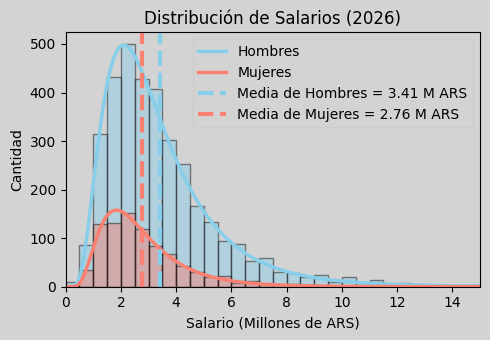

In [63]:
# Variables nuevas (salarios en millones)
sal_A = df_fulltime.loc[df_fulltime['profile_g'] == 'Varón cis']['salary_monthly_NETO']*1e-6
sal_B = df_fulltime.loc[df_fulltime['profile_g'] == 'Mujer cis']['salary_monthly_NETO']*1e-6

# Visualizamos en gráfico de Histogramas

# bins iguales (reducidos para gráfico divulgativo)
bins_2  = np.linspace(0, 15, 31)

# Figura
fig, ax = plt.subplots(1, 1, figsize=(5,3.5))
fig.patch.set_facecolor('lightgrey')
# Ajustes lognormal
plot_lognormal_hist(sal_A, ax, bins_2,
                 color='skyblue', label='Hombres')
plot_lognormal_hist(sal_B, ax, bins_2,
                 color='salmon', label='Mujeres')
# Líneas de las medias
plt.axvline(sal_A.mean(), linestyle='--', linewidth=3, color='skyblue', label=f'Media de Hombres = {sal_A.mean():.2f} M ARS')
plt.axvline(sal_B.mean(), linestyle='--', linewidth=3, color='salmon', label=f'Media de Mujeres = {sal_B.mean():.2f} M ARS')

ax.set_xlim(bins_2[0],bins_2[-1])
ax.set_xlabel('Salario (Millones de ARS)')
ax.set_ylabel('Cantidad')
ax.set_title('Distribución de Salarios (2026)')
ax.set_facecolor('lightgrey')
leg = ax.legend()
leg.get_frame().set_facecolor('lightgrey')
plt.tight_layout()
plt.show()

## Diferencia Salarial para un Mismo Puesto de Trabajo

Para ello, observaremos en primera instancia cuales son los puestos más representativos por genero

In [64]:
# Análisis según puesto
# Cuáles son los puestos mas frecuentes?
print(f'Puestos más frecuentes varones \n {df_fulltime[df_fulltime['profile_g'] == 'Varón cis']['company_main_activity'].value_counts().head(5)}')
print(f'\n Puestos más frecuentes mujeres \n {df_fulltime[df_fulltime['profile_g'] == 'Mujer cis']['company_main_activity'].value_counts().head(5)}')

Puestos más frecuentes varones 
 company_main_activity
Developer                  1262
SysAdmin / DevOps / SRE     466
Manager / Director          328
Technical Leader            290
QA / Tester                 119
Name: count, dtype: int64

 Puestos más frecuentes mujeres 
 company_main_activity
Developer                    215
QA / Tester                   89
Manager / Director            74
UX/UI Designer                69
BI Analyst / Data Analyst     53
Name: count, dtype: int64


Nos concentraremos en los puestos de  **Developer, QA / Tester** y **Manager / Director**. Siendo estos los tres más frecuentes para las mujeres.

In [65]:
# Armamos las subcategorías de hombres y mujeres en cada puesto
puestos = ['Developer','QA / Tester','Manager / Director']
# Subgrupos
dev_A = df_fulltime.loc[(df_fulltime['company_main_activity'] == puestos[0]) &
  (df_fulltime['profile_g'] == 'Varón cis')]['salary_monthly_NETO']
dev_B = df_fulltime.loc[(df_fulltime['company_main_activity'] == puestos[0]) &
  (df_fulltime['profile_g'] == 'Mujer cis')]['salary_monthly_NETO']

qa_A  = df_fulltime.loc[(df_fulltime['company_main_activity'] == puestos[1]) &
  (df_fulltime['profile_g'] == 'Varón cis')]['salary_monthly_NETO']
qa_B  = df_fulltime.loc[(df_fulltime['company_main_activity'] == puestos[1]) &
  (df_fulltime['profile_g'] == 'Mujer cis')]['salary_monthly_NETO']
man_A  = df_fulltime.loc[(df_fulltime['company_main_activity'] == puestos[2]) &
  (df_fulltime['profile_g'] == 'Varón cis')]['salary_monthly_NETO']
man_B  = df_fulltime.loc[(df_fulltime['company_main_activity'] == puestos[2]) &
  (df_fulltime['profile_g'] == 'Mujer cis')]['salary_monthly_NETO']

# Data de salarios según puesto en millones de ARS
data = [dev_A*1e-6, dev_B*1e-6, qa_A*1e-6, qa_B*1e-6, man_A*1e-6, man_B*1e-6]

# Diferencia de Medias
dev_diff = dev_A.mean() - dev_B.mean()
qa_diff = qa_A.mean() - qa_B.mean()
man_diff = man_A.mean() - man_B.mean()

# En porcentual:
dev_percent_diff = (dev_diff / dev_B.mean()) * 100
qa_percent_diff = (qa_diff / qa_B.mean()) * 100
man_percent_diff = (man_diff / man_B.mean()) * 100

print(f"Diferencia de media salarial para {puestos[0]} (Varón cis - Mujer cis): {dev_diff/1e6:.2f} M ARS ({dev_percent_diff:.2f}%)")
print(f"Diferencia de media salarial para {puestos[1]} (Varón cis - Mujer cis): {qa_diff/1e6:.2f} M ARS ({qa_percent_diff:.2f}%)")
print(f"Diferencia de media salarial para {puestos[2]} (Varón cis - Mujer cis): {man_diff/1e6:.2f} M ARS ({man_percent_diff:.2f}%)")

Diferencia de media salarial para Developer (Varón cis - Mujer cis): 0.51 M ARS (18.85%)
Diferencia de media salarial para QA / Tester (Varón cis - Mujer cis): 0.18 M ARS (8.66%)
Diferencia de media salarial para Manager / Director (Varón cis - Mujer cis): 0.98 M ARS (25.95%)


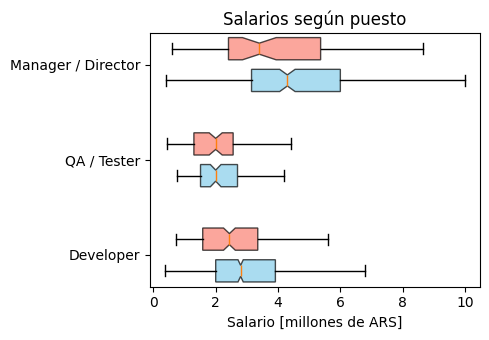

In [66]:
# Boxplots

# Posiciones agrupadas en pares
pos = [1, 2, 4, 5, 7, 8]

fig, ax = plt.subplots(figsize=(5,3.5))

bp = ax.boxplot(
    data,
    vert=False,
    positions=pos,
    widths=0.7,
    patch_artist=True,
    showfliers=False,
    notch=True
)

# colores alternados: A azul, B naranja
colors = ['skyblue', 'salmon'] * 3

for box, c in zip(bp['boxes'], colors):
    box.set_facecolor(c)
    box.set_alpha(0.7)

ax.set_yticks([1.5, 4.5, 7.5])
ax.set_yticklabels([puestos[0], puestos[1], puestos[2]])

ax.set_xlabel("Salario [millones de ARS]")
ax.set_title("Salarios según puesto")

plt.tight_layout()
plt.show()


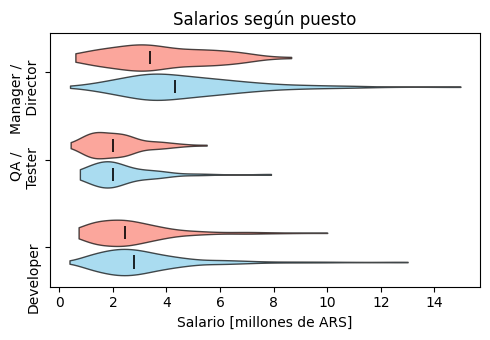

In [67]:
# Violinplot
fig, ax = plt.subplots(figsize=(5,3.5))

vp = ax.violinplot(
    data,
    positions=pos,
    vert=False,
    widths=0.9,
    showmeans=False,
    showmedians=True,
    showextrema=False
)

# Colores alternados
colors = ['skyblue', 'salmon'] * 3

for body, c in zip(vp['bodies'], colors):
    body.set_facecolor(c)
    body.set_edgecolor('black')
    body.set_alpha(0.7)

# Color mediana
vp['cmedians'].set_color('black')
vp['cmedians'].set_linewidth(1.2)

ax.set_yticks([1.5, 4.5, 7.5])
ax.set_yticklabels(["Developer", "QA / \n Tester", "Manager / \n Director"], rotation=90)

ax.set_xlabel("Salario [millones de ARS]")
ax.set_title("Salarios según puesto")

plt.tight_layout()
plt.show()

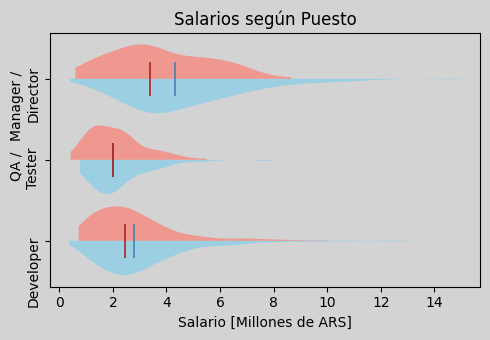

In [68]:
# Violinplot apareados
fig, ax = plt.subplots(figsize=(5,3.5))

pares = [(data[0], data[1]), (data[2], data[3]), (data[4], data[5])]
ypos = [1, 3, 5]

for i, (izq, der) in enumerate(pares):

    # izquierda
    vp1 = ax.violinplot(
        [izq], positions=[ypos[i]], vert=False,
        widths=1.7, showmedians=True, showextrema=False
    )

    for b in vp1['bodies']:
        b.set_facecolor('skyblue')
        b.set_alpha(0.7)
        verts = b.get_paths()[0].vertices
        verts[:,1] = np.minimum(verts[:,1], ypos[i])

    # líneas izquierda
    for k in ['cmedians']:
        vp1[k].set_color('steelblue')
        vp1[k].set_linewidth(1.2)


    # derecha
    vp2 = ax.violinplot(
        [der], positions=[ypos[i]], vert=False,
        widths=1.7, showmedians=True, showextrema=False
    )

    for b in vp2['bodies']:
        b.set_facecolor('salmon')
        b.set_alpha(0.7)
        verts = b.get_paths()[0].vertices
        verts[:,1] = np.maximum(verts[:,1], ypos[i])

    # líneas derecha
    for k in ['cmedians']:
        vp2[k].set_color('firebrick')
        vp2[k].set_linewidth(1.2)

ax.set_yticks(ypos)
ax.set_yticklabels(
    ["Developer", "QA / \nTester", "Manager / \nDirector"],
    rotation=90
)

ax.set_xlabel("Salario [Millones de ARS]")
ax.set_title("Salarios según Puesto")

import matplotlib.patches as mpatches
skyblue_patch = mpatches.Patch(color='skyblue', label='Varones')
salmon_patch = mpatches.Patch(color='salmon', label='Mujeres')

plt.gca().set_facecolor('lightgrey')
fig.patch.set_facecolor('lightgrey')

plt.tight_layout()
plt.show()

## Analizamos la Diferencia Salarial según el Nivel de Estudios

¿Tener un título universitario explica la brecha salarial?


Armamos un diccionario para quedarnos con solo dos categorías: universitarios y no universitarios

In [69]:
# Diccionario
new_studies_label = {
    'Universitario': 'Universitario',
    'Terciario': 'No Universitario',
    'Secundario': 'No Universitario',
    'Primario': 'No Universitario',
    'Doctorado': 'Universitario',
    'Posgrado/Especialización': 'Universitario',
    'Maestría': 'Universitario',
    'Posdoctorado': 'Universitario'
}

df_fulltime_studies = df_fulltime.copy() # Create a copy of the DataFrame
df_fulltime_studies['profile_studies_level'] = df_fulltime_studies['profile_studies_level'].replace(new_studies_label).fillna('No Registrado') # Fill NaN values as well

# Análisis según nivel de estudio

# Subgrupos
univ_A  = df_fulltime_studies.loc[(df_fulltime_studies['profile_studies_level'] == 'Universitario') &
  (df_fulltime_studies['profile_g'] == 'Varón cis')]['salary_monthly_NETO']
univ_B  = df_fulltime_studies.loc[(df_fulltime_studies['profile_studies_level'] == 'Universitario') &
  (df_fulltime_studies['profile_g'] == 'Mujer cis')]['salary_monthly_NETO']
nouniv_A = df_fulltime_studies.loc[(df_fulltime_studies['profile_studies_level'] == 'No Universitario') &
  (df_fulltime_studies['profile_g'] == 'Varón cis')]['salary_monthly_NETO']
nouniv_B = df_fulltime_studies.loc[(df_fulltime_studies['profile_studies_level'] == 'No Universitario') &
  (df_fulltime_studies['profile_g'] == 'Mujer cis')]['salary_monthly_NETO']

data_studies = [univ_A*1e-6, univ_B*1e-6, nouniv_A*1e-6, nouniv_B*1e-6]

# Cuál es la población en cada categoria?
print(f'Varones universitarios: {len(univ_A)}. ({len(univ_A)/len(df)*100:.0f}% de los encuestados)')
print(f'Mujeres universitarias: {len(univ_B)}. ({len(univ_B)/len(df)*100:.0f}% de los encuestados)')
print(f'Varones no universitarios: {len(nouniv_A)}. ({len(nouniv_A)/len(df)*100:.0f}% de los encuestados)')
print(f'Mujeres no universitarias: {len(nouniv_B)}. ({len(nouniv_B)/len(df)*100:.1f}% de los encuestados)')

Varones universitarios: 978. (20% de los encuestados)
Mujeres universitarias: 280. (6% de los encuestados)
Varones no universitarios: 237. (5% de los encuestados)
Mujeres no universitarias: 61. (1.2% de los encuestados)


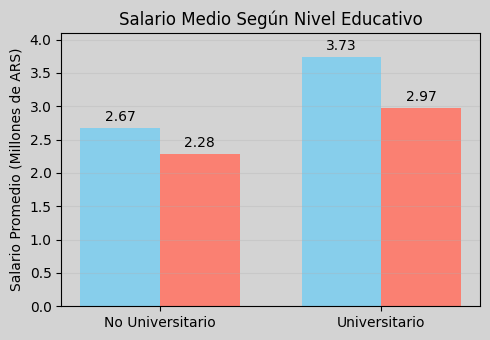

In [70]:
# Barplot de medias
# medias categorizadas
mean_studies_A = [nouniv_A.mean()*1e-6, univ_A.mean()*1e-6]
mean_studies_B = [nouniv_B.mean()*1e-6, univ_B.mean()*1e-6]

x = np.arange(2)
w = 0.36
# Figura
fig, ax = plt.subplots(figsize=(5,3.5))

b1 = ax.bar(x - w/2, mean_studies_A, width=w, color='skyblue', label='Varones')
b2 = ax.bar(x + w/2, mean_studies_B, width=w, color='salmon', label='Mujeres')

# etiquetas sobre barras
ax.bar_label(b1, fmt='%.2f', padding=3, fontsize=10)
ax.bar_label(b2, fmt='%.2f', padding=3, fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(['No Universitario', 'Universitario'])

ax.set_title("Salario Medio Según Nivel Educativo")
#ax.set_xlabel("Nivel Educativo")
ax.set_ylabel("Salario Promedio (Millones de ARS)")
ax.set_ylim(0, 4.1)
ax.grid(axis='y', alpha=0.3)

fig.patch.set_facecolor('lightgrey')
ax.set_facecolor('lightgrey')

#ax.legend()

plt.tight_layout()
plt.show()

In [71]:
mean_groupA = groupA.mean()
mean_groupB = groupB.mean()

difference_of_means = mean_groupA - mean_groupB
percentage_difference = (difference_of_means / mean_groupB) * 100


# Universitario
diff_univ = univ_A.mean() - univ_B.mean()
perc_diff_univ = (diff_univ / univ_B.mean()) * 100
print(f"Diferencia de medias (Varón cis Universitario - Mujer cis Universitaria): {diff_univ:,.2f} ARS")
print(f"Diferencia porcentual (Varón cis Universitario - Mujer cis Universitaria): {perc_diff_univ:.2f}%\n")

# No Universitario
diff_nouniv = nouniv_A.mean() - nouniv_B.mean()
perc_diff_nouniv = (diff_nouniv / nouniv_B.mean()) * 100
print(f"Diferencia de medias (Varón cis No Universitario - Mujer cis No Universitaria): {diff_nouniv:,.2f} ARS")
print(f"Diferencia porcentual (Varón cis No Universitario - Mujer cis No Universitaria): {perc_diff_nouniv:.2f}%\n")

# 2. Mujeres universitarias vs varones no universitarios
diff_woman_univ_vs_man_nouniv = univ_B.mean() - nouniv_A.mean()
perc_diff_woman_univ_vs_man_nouniv = (diff_woman_univ_vs_man_nouniv / nouniv_A.mean()) * 100
print(f"Diferencia de medias (Mujer cis Universitaria - Varón cis No Universitario): {diff_woman_univ_vs_man_nouniv:,.2f} ARS")
print(f"Diferencia porcentual (Mujer cis Universitaria - Varón cis No Universitario): {perc_diff_woman_univ_vs_man_nouniv:.2f}%")

Diferencia de medias (Varón cis Universitario - Mujer cis Universitaria): 758,572.91 ARS
Diferencia porcentual (Varón cis Universitario - Mujer cis Universitaria): 25.52%

Diferencia de medias (Varón cis No Universitario - Mujer cis No Universitaria): 389,289.58 ARS
Diferencia porcentual (Varón cis No Universitario - Mujer cis No Universitaria): 17.07%

Diferencia de medias (Mujer cis Universitaria - Varón cis No Universitario): 302,886.82 ARS
Diferencia porcentual (Mujer cis Universitaria - Varón cis No Universitario): 11.34%
